# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Левченко Денис'
LIST_NUMBER  = 4

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 4, файл lr6_варіант_04.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
TYPE_OF_TASK = 'класифікація'
TYPE_WHY = 'ціль «відтік» має два значення (1 — розірвав договір, 0 — лишився), тож модель оцінює ймовірність класу 1'

METRIC = 'AUC'
METRIC_WHY = ('відтоку лише 15–30 %, тож модель «ніхто не піде» має точність 70–85 % без жодної користі; '
              'AUC не залежить від порога і показує, чи ставить модель тих, хто піде, вище за тих, хто лишиться')

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'
CV_WHY = ('1200 клієнтів замало для одного відкладеного поділу: 20 навчань дають середнє і розкид, '
          'а стратифікація тримає однакову частку відтоку в кожній згортці')

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')
for nme, val, why in [('тип задачі', TYPE_OF_TASK, TYPE_WHY), ('метрика', METRIC, METRIC_WHY), ('схема', CV_SCHEME, CV_WHY)]:
    print('%-10s: %s — %s' % (nme, val, why))

рішення зафіксовані
тип задачі: класифікація — ціль «відтік» має два значення (1 — розірвав договір, 0 — лишився), тож модель оцінює ймовірність класу 1
метрика   : AUC — відтоку лише 15–30 %, тож модель «ніхто не піде» має точність 70–85 % без жодної користі; AUC не залежить від порога і показує, чи ставить модель тих, хто піде, вище за тих, хто лишиться
схема     : стратифікована 5-кратна, 4 повтори — 1200 клієнтів замало для одного відкладеного поділу: 20 навчань дають середнє і розкид, а стратифікація тримає однакову частку відтоку в кожній згортці


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.273

типи стовпців: {'object': 13, 'float64': 8, 'int64': 5}


In [6]:
info = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'унікальних': raw.nunique(),
    '% пропусків': (raw.isna().mean() * 100).round(1),
    'приклад': [raw[c].dropna().iloc[0] for c in raw.columns],
})
info.index.name = 'стовпець'
info = info.sort_values('% пропусків', ascending=False)
display(info)

BASELINE_ACC = 1 - raw[TARGET].mean()
print('рядків %d, стовпців %d' % raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print('точність моделі «ніхто не піде»: %.3f' % BASELINE_ACC)
print('стовпців із невизначеним типом (object): %d' % (raw.dtypes == object).sum())
print('найбільше пропусків: %s — %.1f %%' % (info.index[0], info['% пропусків'].iloc[0]))

,тип,унікальних,% пропусків,приклад
стовпець,,,,
код_причини_закриття,object,5,72.8,ПЕР-01
сума_повернення_депозиту,float64,325,72.8,304.26
середній_час_відповіді_хв,float64,265,33.3,1.0
трафік_ГБ,object,962,5.0,50.9
щомісячний_платіж,object,1127,4.0,315.85
аварій_на_ділянці_за_квартал,float64,5,3.0,0.0
id_клієнта,object,1200,0.0,K40000
оцінка_ризику_менеджером,float64,5,0.0,3.0
дата_підключення,object,597,0.0,2024-12-21


рядків 1200, стовпців 26
частка відтоку: 0.273
точність моделі «ніхто не піде»: 0.728
стовпців із невизначеним типом (object): 13
найбільше пропусків: код_причини_закриття — 72.8 %


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
obj = raw.select_dtypes('object')
as_num = obj.apply(lambda s: pd.to_numeric(s, errors='coerce'))
share = (as_num.notna().sum() / obj.notna().sum()).round(3)
display(share[share > 0.5].to_frame('частка значень, що читаються як число'))

for c in share[share > 0.5].index:
    bad = obj.loc[as_num[c].isna() & obj[c].notna(), c]
    print('%s: %d значень не читаються як число, приклади: %s' % (c, len(bad), bad.unique()[:5].tolist()))

miss = raw['середній_час_відповіді_хв'].isna().rename('час відповіді пропущено')
display(pd.crosstab(miss, raw['кількість_звернень_у_підтримку']))
display(raw.groupby(miss)[TARGET].agg(частка_відтоку='mean', клієнтів='size').round(3))

,"частка значень, що читаються як число"
стовпець,
щомісячний_платіж,0.977
трафік_ГБ,0.997


щомісячний_платіж: 27 значень не читаються як число, приклади: ['205.49 грн', '199.39 грн', '208.14 грн', '263.93 грн', '235.74 грн']
трафік_ГБ: 3 значень не читаються як число, приклади: ['1900-01-06 00:00:00', '1900-01-11 00:00:00', '1900-01-27 00:00:00']


кількість_звернень_у_підтримку,0,1,2,3,4,5
час відповіді пропущено,,,,,,
False,0,437,227,108,22,6
True,400,0,0,0,0,0


,частка_відтоку,клієнтів
час відповіді пропущено,,
False,0.312,800
True,0.192,400


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'
PROBLEM_MNAR           = 'середній_час_відповіді_хв'

_m = raw[PROBLEM_MNAR].isna()
assert (raw.loc[_m, 'кількість_звернень_у_підтримку'] == 0).all()
MNAR_MEANING = ('пропуск означає, що клієнт за квартал жодного разу не звертався в підтримку: '
                'усі %d пропусків стоять у рядках із кількість_звернень_у_підтримку = 0, тож часу відповіді просто не існує'
                % _m.sum())

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')
print(MNAR_MEANING)

проблеми названо
пропуск означає, що клієнт за квартал жодного разу не звертався в підтримку: усі 400 пропусків стоять у рядках із кількість_звернень_у_підтримку = 0, тож часу відповіді просто не існує


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        if v is None or isinstance(v, (datetime.date, np.datetime64)):
            return np.nan
        if isinstance(v, (int, float, np.number)):
            return float(v)
        t = str(v).strip()
        if re.match(r'\d{4}-\d{2}-\d{2}', t):
            return np.nan
        m = re.match(r'[-+]?\d+(?:[.,]\d+)?', t)
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)

_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
assert np.isnan(to_number(pd.Series(['НОМ-035']))[0]), 'код серії — не число'
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']
CANON = {'чол': 'ч', 'жін': 'ж'}
DATE_ORIGIN = pd.Timestamp('2023-01-01')

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        if c == 'дата_підключення':
            X[c] = (pd.to_datetime(s, errors='coerce') - DATE_ORIGIN).dt.days.astype(float)
            kind, how = 'число', 'днів від 2023-01-01'
        elif s.dtype == object:
            v = to_number(s)
            if v.notna().sum() > 0.8 * s.notna().sum():
                X[c] = v
                kind, how = 'число', 'to_number, NaN після розбору: %d' % v.isna().sum()
            else:
                t = s.astype(str).str.strip().str.lower().replace(CANON).where(s.notna())
                X[c] = t.astype('category')
                kind, how = 'категорія', '%d рівнів' % X[c].nunique()
        else:
            X[c] = s.astype(float)
            kind, how = 'число', 'як є'
        log.append({'стовпець': c, 'рішення': kind, 'як': how})
    return X, pd.DataFrame(log)

X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 9


,стовпець,рішення,як
0,вік,число,як є
1,стать,категорія,2 рівнів
2,місто,категорія,6 рівнів
3,філія,категорія,6 рівнів
4,тариф,категорія,4 рівнів
5,тип_підключення,категорія,3 рівнів
6,спосіб_оплати,категорія,3 рівнів
7,автоплатіж,категорія,2 рівнів
8,кількість_послуг,число,як є
9,місяців_обслуговування,число,як є


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    num = [c for c in X.columns if str(X[c].dtype) != 'category']
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
    ])
    return Pipeline([('prep', prep), ('clf', clf)])

def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.993


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.993 ± 0.003
час      : 0.2 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = ('AUC %.3f — майже ідеальний поділ, якого на реальних даних про відтік не буває (добра модель дає 0,8–0,9); '
                  'з двох причин високої AUC спрацювала не легкість задачі, а витік: у вивантаженні є поля, '
                  'записані вже після того, як клієнт пішов' % auc_naive.mean())
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0.993 — майже ідеальний поділ, якого на реальних даних про відтік не буває (добра модель дає 0,8–0,9); з двох причин високої AUC спрацювала не легкість задачі, а витік: у вивантаженні є поля, записані вже після того, як клієнт пішов


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n1, n0 = int(filled.sum()), int((~filled).sum())
        score = np.nan
        if n1 >= min_group and n0 >= min_group:
            a = roc_auc_score(y, filled.astype(int))
            score = max(a, 1 - a)
        rows.append({'ознака': c, 'заповнено': n1,
                     'частка_відтоку_де_заповнено': round(y[filled].mean(), 3) if n1 else np.nan,
                     'частка_відтоку_де_пропуск': round(y[~filled].mean(), 3) if n0 else np.nan,
                     'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)

scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,сума_повернення_депозиту,327,1.000,0.000,1.000000
23,код_причини_закриття,327,1.000,0.000,1.000000
17,середній_час_відповіді_хв,800,0.312,0.192,0.567257
14,трафік_ГБ,1140,0.274,0.250,0.502837
12,щомісячний_платіж,1152,0.272,0.292,0.501934
16,аварій_на_ділянці_за_квартал,1164,0.273,0.250,0.501702
0,id_клієнта,1200,0.272,NaN,NaN
1,вік,1200,0.272,NaN,NaN
2,стать,1200,0.272,NaN,NaN
3,місто,1200,0.272,NaN,NaN


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK_WHY = {
    'сума_повернення_депозиту': 'депозит повертають лише при закритті договору, а в момент дзвінка договір чинний',
    'код_причини_закриття': 'причину закриття записують, коли договір уже розірвано, до того поле порожнє',
}
TARGET_LEAK = list(TARGET_LEAK_WHY)
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)
for c, why in TARGET_LEAK_WHY.items():
    print('   %s — %s' % (c, why))

цільовий витік: ['сума_повернення_депозиту', 'код_причини_закриття']
   сума_повернення_депозиту — депозит повертають лише при закритті договору, а в момент дзвінка договір чинний
   код_причини_закриття — причину закриття записують, коли договір уже розірвано, до того поле порожнє


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.972 ± 0.008


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
print(list(X2.columns))

solo = {}
for c in X2.columns:
    v = X2[c].cat.codes if str(X2[c].dtype) == 'category' else X2[c].fillna(X2[c].median())
    a = roc_auc_score(y, v)
    solo[c] = max(a, 1 - a)
solo = pd.Series(solo).sort_values(ascending=False)
display(solo.round(3).head(6).to_frame('AUC однієї ознаки'))

manager = raw.groupby('оцінка_ризику_менеджером')[TARGET].agg(частка_відтоку='mean', клієнтів='size').round(3)
display(manager)

TIMELINE = pd.DataFrame([
    ('id_клієнта', 'при реєстрації', 'викинути: ідентифікатор, модель його лише запам’ятовує'),
    ('сума_повернення_депозиту', 'у день закриття договору', 'викинути: цільовий витік'),
    ('код_причини_закриття', 'у момент розірвання договору', 'викинути: цільовий витік'),
    ('оцінка_ризику_менеджером', 'після розмов менеджера з клієнтом, коли той уже показав намір піти', 'викинути: оцінка людини'),
    ('річний_платіж', 'при укладенні договору, ≈ 12 щомісячних', 'лишити: існує в момент прогнозу, дублює щомісячний платіж'),
    ('номер_договору_серія', 'при укладенні договору', 'лишити: існує в момент прогнозу, але це код, а не кількість'),
    ('скоринг_партнера', 'при підключенні, від партнера', 'лишити: існує в момент прогнозу; AUC однієї ознаки %.3f' % solo['скоринг_партнера']),
    ('філія', 'при підключенні', 'існує в момент прогнозу, але перевірити на артефакт збору (розділ 6)'),
], columns=['стовпець', 'коли з’являється в житті клієнта', 'рішення']).set_index('стовпець')
display(TIMELINE)

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'номер_договору_серія', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


,AUC однієї ознаки
оцінка_ризику_менеджером,0.947
річний_платіж,0.692
щомісячний_платіж,0.687
швидкість_тарифу_Мбіт,0.670
місяців_обслуговування,0.655
вік,0.621


,частка_відтоку,клієнтів
оцінка_ризику_менеджером,,
1.0,0.000,237
2.0,0.027,405
3.0,0.222,279
4.0,0.867,188
5.0,1.000,91


,коли з’являється в житті клієнта,рішення
стовпець,,
id_клієнта,при реєстрації,"викинути: ідентифікатор, модель його лише запа..."
сума_повернення_депозиту,у день закриття договору,викинути: цільовий витік
код_причини_закриття,у момент розірвання договору,викинути: цільовий витік
оцінка_ризику_менеджером,"після розмов менеджера з клієнтом, коли той уж...",викинути: оцінка людини
річний_платіж,"при укладенні договору, ≈ 12 щомісячних","лишити: існує в момент прогнозу, дублює щоміся..."
номер_договору_серія,при укладенні договору,"лишити: існує в момент прогнозу, але це код, а..."
скоринг_партнера,"при підключенні, від партнера",лишити: існує в момент прогнозу; AUC однієї оз...
філія,при підключенні,"існує в момент прогнозу, але перевірити на арт..."


In [18]:
HUMAN_LEAK = ['оцінка_ризику_менеджером']
HUMAN_LEAK_WHEN = ('оцінку 1–5 ставить менеджер після спілкування з клієнтом, коли вже чув його скарги '
                   'і, можливо, намір піти')
HUMAN_LEAK_WHY = ('поле заповнене в усіх %d клієнтів, тож факт заповненості не відрізняє класи, а детектор 5.1 дивиться лише на пропуски; '
                  'витік сидить у самих значеннях: при оцінці 1 пішли %.0f %%, при оцінці 5 — %.0f %%, бо менеджер оцінював поведінку, '
                  'яку модель мала б передбачити'
                  % (raw['оцінка_ризику_менеджером'].notna().sum(), manager['частка_відтоку'].iloc[0] * 100,
                     manager['частка_відтоку'].iloc[-1] * 100))

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))
print(HUMAN_LEAK_WHY)

після вилучення оцінок людини: 21 ознак, AUC 0.846 ± 0.029
поле заповнене в усіх 1200 клієнтів, тож факт заповненості не відрізняє класи, а детектор 5.1 дивиться лише на пропуски; витік сидить у самих значеннях: при оцінці 1 пішли 0 %, при оцінці 5 — 100 %, бо менеджер оцінював поведінку, яку модель мала б передбачити


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка,клієнтів
філія,,
Ф-01 Центр,0.394,216
Ф-02 Захід,0.325,200
Ф-03 Схід,0.228,189
Ф-04 Південь,0.241,195
Ф-05 Північ,0.262,195
Ф-06 Приміська,0.176,205


дата_підключення,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4
частка,0.292,0.308,0.303,0.23,0.264,0.269,0.316,0.204
клієнтів,144.000,146.000,152.000,178.00,125.000,145.000,158.000,152.000


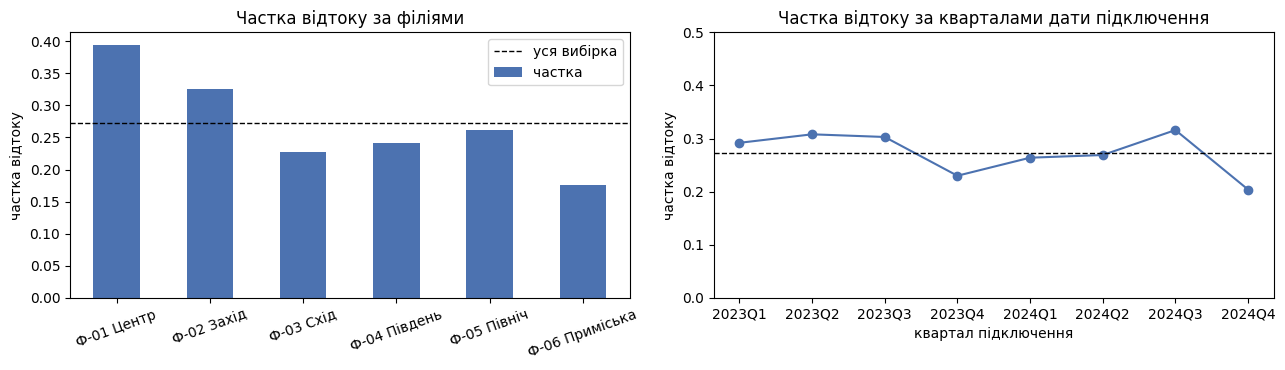

,факт,очікувано за ознаками,надлишок
філія,,,
Ф-01 Центр,0.394,0.296,0.098
Ф-02 Захід,0.325,0.257,0.068
Ф-03 Схід,0.228,0.271,-0.044
Ф-04 Південь,0.241,0.291,-0.050
Ф-05 Північ,0.262,0.280,-0.018
Ф-06 Приміська,0.176,0.238,-0.062


In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

by_branch = raw.groupby('філія')[TARGET].agg(частка='mean', клієнтів='size').round(3)
display(by_branch)

conn = pd.to_datetime(raw['дата_підключення'])
by_q = raw.groupby(conn.dt.to_period('Q').astype(str))[TARGET].agg(частка='mean', клієнтів='size').round(3)
display(by_q.T)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
by_branch['частка'].plot.bar(ax=ax[0], color='#4C72B0', rot=20)
ax[0].axhline(raw[TARGET].mean(), color='k', ls='--', lw=1, label='уся вибірка')
ax[0].set_title('Частка відтоку за філіями')
ax[0].set_xlabel('')
ax[0].set_ylabel('частка відтоку')
ax[0].legend()
by_q['частка'].plot(ax=ax[1], marker='o', color='#4C72B0')
ax[1].axhline(raw[TARGET].mean(), color='k', ls='--', lw=1)
ax[1].set_ylim(0, 0.5)
ax[1].set_title('Частка відтоку за кварталами дати підключення')
ax[1].set_xlabel('квартал підключення')
ax[1].set_ylabel('частка відтоку')
plt.tight_layout()
plt.show()

X3n = X3.drop(columns=['філія'])
p_oof = cross_val_predict(make_pipe(X3n, logreg()), X3n, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                          method='predict_proba')[:, 1]
excess = pd.DataFrame({'факт': y, 'очікувано за ознаками': p_oof, 'філія': raw['філія']}).groupby('філія').mean()
excess['надлишок'] = excess['факт'] - excess['очікувано за ознаками']
display(excess.round(3))

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'філія'
assert SUSPECT in ('філія', 'дата_підключення')

SUSPECT_BRANCHES = by_branch.index[by_branch['частка'] > 0.30].tolist()
source = raw['філія'].isin(SUSPECT_BRANCHES).astype(int)
print('філії-підозрювані: %s, клієнтів у них: %d' % (', '.join(SUSPECT_BRANCHES), source.sum()))
branch_profile = raw.groupby(source.map({1: 'Центр і Захід', 0: 'інші філії'}))[['вік', 'швидкість_тарифу_Мбіт']].mean().round(1)
display(branch_profile)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

late = (conn >= '2024-01-01').astype(int)
X4d, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + ['дата_підключення'])
auc_src_date = cross_val_score(make_pipe(X4d, logreg()), X4d, late, cv=cv, scoring='roc_auc')
speed_by_year = raw.groupby(late)['швидкість_тарифу_Мбіт'].mean()
print('для порівняння, ПЕРІОД підключення (з 2024 року): AUC %.3f — але це швидкість тарифів (%.0f Мбіт у 2024 проти %.0f у 2023), '
      'а сходинки у відтоку за кварталами немає, тож підозрюю філію' % (auc_src_date.mean(), speed_by_year[1], speed_by_year[0]))

філії-підозрювані: Ф-01 Центр, Ф-02 Захід, клієнтів у них: 416


стовпець,вік,швидкість_тарифу_Мбіт
філія,,
Центр і Захід,37.1,353.6
інші філії,41.7,283.8


ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.692
ті самі ознаки передбачають ВІДТІК  : AUC 0.834 ± 0.031


для порівняння, ПЕРІОД підключення (з 2024 року): AUC 0.745 — але це швидкість тарифів (372 Мбіт у 2024 проти 248 у 2023), а сходинки у відтоку за кварталами немає, тож підозрюю філію


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.993
2. мінус цільовий витік,22,0.972
3. мінус оцінки людини,21,0.846
4. мінус артефакт збору,20,0.834


чесне число: 0.834 ± 0.031


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
_sus = by_branch.loc[SUSPECT_BRANCHES, 'частка']
_rest = by_branch.drop(index=SUSPECT_BRANCHES)['частка']
_exc = excess.loc[SUSPECT_BRANCHES, 'надлишок']
DECISION_ARTEFACT = 'викинути'
DECISION_WHY = ('у філіях %s відтік %s проти %.0f–%.0f %% в інших, і це на %.0f–%.0f п. п. більше, ніж пояснюють ознаки самих клієнтів, '
                'тож схоже на інше правило обліку; ті самі чесні ознаки вгадують ці філії з AUC %.3f; з філією AUC відтоку %.3f, '
                'без неї %.3f, тобто філія додає лише %.3f і саме за рахунок артефакту; модель має працювати в будь-якій філії, '
                'тому філію викидаю, а замовникові називаю обидва числа'
                % (' і '.join(SUSPECT_BRANCHES), ' і '.join('%.0f %%' % (v * 100) for v in _sus),
                   _rest.min() * 100, _rest.max() * 100, _exc.min() * 100, _exc.max() * 100,
                   auc_src.mean(), auc3.mean(), auc4.mean(), auc3.mean() - auc4.mean()))
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — у філіях Ф-01 Центр і Ф-02 Захід відтік 39 % і 32 % проти 18–26 % в інших, і це на 7–10 п. п. більше, ніж пояснюють ознаки самих клієнтів, тож схоже на інше правило обліку; ті самі чесні ознаки вгадують ці філії з AUC 0.692; з філією AUC відтоку 0.846, без неї 0.834, тобто філія додає лише 0.012 і саме за рахунок артефакту; модель має працювати в будь-якій філії, тому філію викидаю, а замовникові називаю обидва числа


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round((time.time() - t0) * 100 / cv.get_n_splits(), 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.834,0.031,1.2
одне дерево,0.766,0.032,1.1
випадковий ліс,0.828,0.027,19.7
гістограмний бустинг,0.828,0.028,56.3


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу).

    Різниця b − a по кожній із 20 спільних згорток; інтервал за t-розподілом, t(0,975; 19) = 2,093.
    """
    d = np.asarray(b) - np.asarray(a)
    return d.mean(), 2.093 * d.std(ddof=1) / np.sqrt(len(d))

PAIRED = {}
base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    PAIRED[name] = (m, h)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: -0.0060 ± 0.0108   у межах шуму


гістограмний бустинг   проти логістичної: -0.0064 ± 0.0092   у межах шуму


In [25]:
_c = cmp_models
CHOSEN_MODEL = 'логістична регресія'
CHOSEN_WHY = ('якість: AUC %.3f — найвища, ліс і бустинг нижчі на %.4f і %.4f, але парне порівняння дає ±%.4f і ±%.4f, тобто різниця '
              'в межах шуму, а одне дерево (%.3f) помітно гірше; стабільність: розкид %.3f такий самий, як в інших; швидкість: %.1f с '
              'на 100 навчань проти %.1f у лісу й %.1f у бустингу; інтерпретованість: коефіцієнти читаються напряму. '
              'Частину 2 шаблон веде на випадковому лісі, бо вбудована важливість і TreeExplainer потребують дерев'
              % (_c.loc['логістична регресія', 'AUC'], -PAIRED['випадковий ліс'][0], -PAIRED['гістограмний бустинг'][0],
                 PAIRED['випадковий ліс'][1], PAIRED['гістограмний бустинг'][1], _c.loc['одне дерево', 'AUC'],
                 _c.loc['логістична регресія', '±'], _c.loc['логістична регресія', 'с на 100 навчань'],
                 _c.loc['випадковий ліс', 'с на 100 навчань'], _c.loc['гістограмний бустинг', 'с на 100 навчань']))
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — якість: AUC 0.834 — найвища, ліс і бустинг нижчі на 0.0060 і 0.0064, але парне порівняння дає ±0.0108 і ±0.0092, тобто різниця в межах шуму, а одне дерево (0.766) помітно гірше; стабільність: розкид 0.031 такий самий, як в інших; швидкість: 1.2 с на 100 навчань проти 19.7 у лісу й 56.3 у бустингу; інтерпретованість: коефіцієнти читаються напряму. Частину 2 шаблон веде на випадковому лісі, бо вбудована важливість і TreeExplainer потребують дерев


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
FEATURE_HYPOTHESES = {
    'звернень_на_рік_стажу': 'часті звернення відносно стажу означають, що в клієнта постійно щось не працює',
    'новий_клієнт': 'перший рік обслуговування найризикованіший: звичка ще не склалась, а конкуренти дають акції новим абонентам',
    'аварія_і_звернення': 'аварія на ділянці плюс звернення в підтримку — клієнт уже відчув проблему на собі',
}

def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    F['звернень_на_рік_стажу'] = F['кількість_звернень_у_підтримку'] / F['місяців_обслуговування'].clip(lower=1) * 12
    F['новий_клієнт'] = (F['місяців_обслуговування'] <= 12).astype(float)
    outage = F['аварій_на_ділянці_за_квартал']
    F['аварія_і_звернення'] = ((outage > 0) & (F['кількість_звернень_у_підтримку'] > 0)).astype(float).where(outage.notna())
    return F

X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))
display(pd.Series(FEATURE_HYPOTHESES).to_frame('гіпотеза, яку кодує ознака'))

було 20 ознак, стало 23


,"гіпотеза, яку кодує ознака"
звернень_на_рік_стажу,"часті звернення відносно стажу означають, що в..."
новий_клієнт,перший рік обслуговування найризикованіший: зв...
аварія_і_звернення,аварія на ділянці плюс звернення в підтримку —...


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.834 ± 0.031
приріст проти базового набору: -0.0004 ± 0.0017   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
m5, h5 = paired(base, auc5)
FEATURES_VS_MODEL = ('нові ознаки дали логістичній %+.4f ± %.4f (%s) майже без додаткового часу (%.1f с на 100 навчань); складніша модель: '
                     'ліс %+.4f ± %.4f, бустинг %+.4f ± %.4f (теж у межах шуму) ціною %.1f і %.1f с на 100 навчань; жоден шлях не дав '
                     'приросту, тож для цього набору ні три «очевидні» ознаки, ні складніший метод нічого не додають'
                     % (m5, h5, 'значуще' if abs(m5) > h5 else 'у межах шуму', cmp_models.loc['логістична регресія', 'с на 100 навчань'],
                        *PAIRED['випадковий ліс'], *PAIRED['гістограмний бустинг'],
                        cmp_models.loc['випадковий ліс', 'с на 100 навчань'], cmp_models.loc['гістограмний бустинг', 'с на 100 навчань']))
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

нові ознаки дали логістичній -0.0004 ± 0.0017 (у межах шуму) майже без додаткового часу (1.2 с на 100 навчань); складніша модель: ліс -0.0060 ± 0.0108, бустинг -0.0064 ± 0.0092 (теж у межах шуму) ціною 19.7 і 56.3 с на 100 навчань; жоден шлях не дав приросту, тож для цього набору ні три «очевидні» ознаки, ні складніший метод нічого не додають


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.807
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

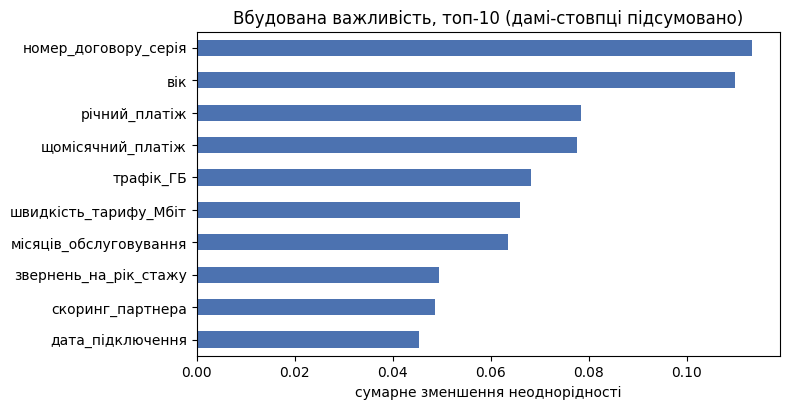

,вбудована важливість
номер_договору_серія,0.1133
вік,0.1098
річний_платіж,0.0784
щомісячний_платіж,0.0777
трафік_ГБ,0.0683
швидкість_тарифу_Мбіт,0.0660
місяців_обслуговування,0.0635
звернень_на_рік_стажу,0.0494
скоринг_партнера,0.0486
дата_підключення,0.0453


In [30]:
prep = model.named_steps['prep']
names = prep.get_feature_names_out()
CAT_COLS = list(prep.transformers_[1][2])

def to_source(n):
    kind, rest = n.split('__', 1)
    if kind == 'num':
        return rest
    return max((c for c in CAT_COLS if rest.startswith(c + '_')), key=len)

gini_imp = (pd.Series(model.named_steps['clf'].feature_importances_, index=names)
            .groupby(to_source).sum().sort_values(ascending=False))
ax = gini_imp.head(10)[::-1].plot.barh(figsize=(8, 4.2), color='#4C72B0')
ax.set_title('Вбудована важливість, топ-10 (дамі-стовпці підсумовано)')
ax.set_xlabel('сумарне зменшення неоднорідності')
plt.tight_layout()
plt.show()
display(gini_imp.head(10).round(4).to_frame('вбудована важливість'))

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.081011
місяців_обслуговування,0.048380
звернень_на_рік_стажу,0.016591
трафік_ГБ,0.014928
швидкість_тарифу_Мбіт,0.014648
щомісячний_платіж,0.013205
річний_платіж,0.010496
автоплатіж,0.006658
середній_час_відповіді_хв,0.005456
аварій_на_ділянці_за_квартал,0.005451


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
both = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp}).sort_values('вбудована', ascending=False)
both['ранг вбудованої'] = np.arange(1, len(both) + 1)
display(both.round(4))

,вбудована,перестановочна,ранг вбудованої
номер_договору_серія,0.1133,-0.0019,1
вік,0.1098,0.0810,2
річний_платіж,0.0784,0.0105,3
щомісячний_платіж,0.0777,0.0132,4
трафік_ГБ,0.0683,0.0149,5
швидкість_тарифу_Мбіт,0.0660,0.0146,6
місяців_обслуговування,0.0635,0.0484,7
звернень_на_рік_стажу,0.0494,0.0166,8
скоринг_партнера,0.0486,0.0031,9
дата_підключення,0.0453,-0.0004,10


In [33]:
_n_levels = FINAL_X['номер_договору_серія'].nunique()
_sizes = FINAL_X['номер_договору_серія'].value_counts()
FAKE_IMPORTANT = 'номер_договору_серія'
FAKE_IMPORTANT_WHY = ('після одиничного кодування серія договору — це %d дамі-стовпців, тобто %d додаткових порогів; серед груп по %d–%d клієнтів '
                      'завжди знайдеться така, де відтік випадково вищий чи нижчий, і на навчальних даних розбиття по ній зменшує неоднорідність; '
                      'тому сумарна вбудована важливість велика (%.3f, %d-е місце), а перемішування серії на перевірковій частині не змінює AUC (%+.4f)'
                      % (_n_levels, _n_levels, _sizes.min(), _sizes.max(), both.loc[FAKE_IMPORTANT, 'вбудована'],
                         both.loc[FAKE_IMPORTANT, 'ранг вбудованої'], both.loc[FAKE_IMPORTANT, 'перестановочна']))
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
assert both.loc[FAKE_IMPORTANT, 'ранг вбудованої'] <= 5 and abs(both.loc[FAKE_IMPORTANT, 'перестановочна']) < 0.005
print('хибно важлива ознака:', FAKE_IMPORTANT)
print(FAKE_IMPORTANT_WHY)

хибно важлива ознака: номер_договору_серія
після одиничного кодування серія договору — це 55 дамі-стовпців, тобто 55 додаткових порогів; серед груп по 10–39 клієнтів завжди знайдеться така, де відтік випадково вищий чи нижчий, і на навчальних даних розбиття по ній зменшує неоднорідність; тому сумарна вбудована важливість велика (0.113, 1-е місце), а перемішування серії на перевірковій частині не змінює AUC (-0.0019)


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
num_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
corr = FINAL_X[num_cols].corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)
display(pairs.head(5).round(4).to_frame('r'))

r
щомісячний_платіж            річний_платіж       0.9993
швидкість_тарифу_Мбіт        щомісячний_платіж   0.7586
                             річний_платіж       0.7556
місяців_обслуговування       новий_клієнт       -0.6057
аварій_на_ділянці_за_квартал аварія_і_звернення  0.6036

In [35]:
from sklearn.base import clone

DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

keep = [c for c in FINAL_X.columns if c != DUP_PAIR[1]]
model_wo = make_pipe(FINAL_X[keep], clone(FINAL_CLF)).fit(Xtr[keep], ytr)
perm_wo = pd.Series(permutation_importance(model_wo, Xte[keep], yte, n_repeats=10, random_state=SEED,
                                           scoring='roc_auc').importances_mean, index=keep)
print('без %s:' % DUP_PAIR[1])
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_wo[DUP_PAIR[0]]))
RANK_FULL = list(perm_imp.index).index(DUP_PAIR[0]) + 1
RANK_WO = list(perm_wo.sort_values(ascending=False).index).index(DUP_PAIR[0]) + 1
print('ранг %s за перестановочною: у повній моделі %d, без пари %d' % (DUP_PAIR[0], RANK_FULL, RANK_WO))

у повній моделі:
   щомісячний_платіж            +0.0132
   річний_платіж                +0.0105


без річний_платіж:
   щомісячний_платіж            +0.0279
ранг щомісячний_платіж за перестановочною: у повній моделі 6, без пари 4


In [36]:
DUP_EXPLANATION = ('r = %.4f: річний платіж — це приблизно 12 щомісячних, тобто та сама інформація; у повній моделі перестановочна важливість '
                   'обох помірна (%.4f і %.4f), бо після перемішування однієї модель бере платіж із другої; без пари важливість '
                   'щомісячного платежу зросла до %.4f; метод чесно відповідає, наскільки гірше без однієї ознаки, а хибний лише висновок '
                   '«важливість мала, отже можна викинути обидві»'
                   % (corr.loc[DUP_PAIR[0], DUP_PAIR[1]], perm_imp[DUP_PAIR[0]], perm_imp[DUP_PAIR[1]], perm_wo[DUP_PAIR[0]]))
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

r = 0.9993: річний платіж — це приблизно 12 щомісячних, тобто та сама інформація; у повній моделі перестановочна важливість обох помірна (0.0132 і 0.0105), бо після перемішування однієї модель бере платіж із другої; без пари важливість щомісячного платежу зросла до 0.0279; метод чесно відповідає, наскільки гірше без однієї ознаки, а хибний лише висновок «важливість мала, отже можна викинути обидві»


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

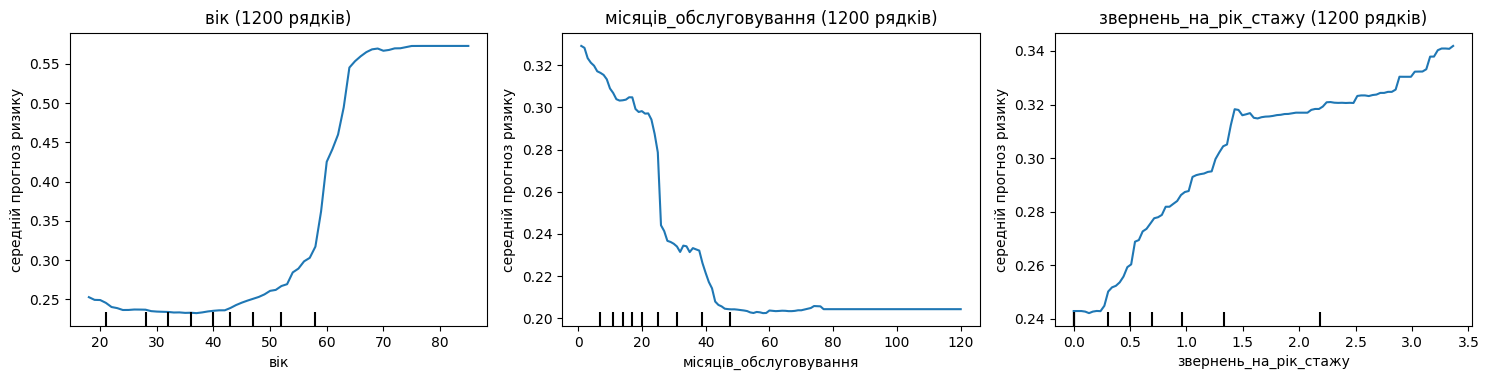

три найважливіші числові ознаки за перестановочною важливістю: ['вік', 'місяців_обслуговування', 'звернень_на_рік_стажу']
рядків із пропуском у них: {'вік': 0, 'місяців_обслуговування': 0, 'звернень_на_рік_стажу': 0}
вік                      від 0.253 при 18.00 до 0.573 при 85.00; мінімум 0.233 при 37.00, максимум 0.573 при 77.00; найрізкіша зміна між 59.00 і 60.00
місяців_обслуговування   від 0.329 при 1.00 до 0.204 при 120.00; мінімум 0.202 при 58.00, максимум 0.329 при 1.00; найрізкіша зміна між 25.00 і 26.00
звернень_на_рік_стажу    від 0.243 при 0.00 до 0.342 при 3.36; мінімум 0.242 при 0.14, максимум 0.342 при 3.36; найрізкіша зміна між 0.51 і 0.54

вік: ризик майже не змінюється до середнього віку з неглибоким мінімумом, а потім різко зростає — форма немонотонна (розділ 10.2)
місяців_обслуговування: ризик спадає зі стажем, найрізкіше — близько двох років; хто пережив два роки, частіше лишається
звернень_на_рік_стажу: що частіше клієнт звертається в підтримку відносно стажу, то в

In [37]:
from sklearn.inspection import PartialDependenceDisplay

top3 = [c for c in perm_imp.index if c in num_cols][:3]
pdp_res = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
for ax, c in zip(axes, top3):
    sub = FINAL_X[FINAL_X[c].notna()]
    disp = PartialDependenceDisplay.from_estimator(model, sub, [c], kind='average', ax=ax)
    disp.axes_[0][0].set_ylabel('середній прогноз ризику')
    disp.axes_[0][0].set_title('%s (%d рядків)' % (c, len(sub)))
    pdp_res[c] = disp.pd_results[0]
plt.tight_layout()
plt.show()
print('три найважливіші числові ознаки за перестановочною важливістю:', top3)
print('рядків із пропуском у них:', {c: int(FINAL_X[c].isna().sum()) for c in top3})

PDP_READING = {}
for c in top3:
    g, v = pdp_res[c]['grid_values'][0], pdp_res[c]['average'][0]
    i = int(np.argmax(np.abs(np.diff(v))))
    PDP_READING[c] = ('від %.3f при %.2f до %.3f при %.2f; мінімум %.3f при %.2f, максимум %.3f при %.2f; найрізкіша зміна між %.2f і %.2f'
                      % (v[0], g[0], v[-1], g[-1], v.min(), g[v.argmin()], v.max(), g[v.argmax()], g[i], g[i + 1]))
    print('%-24s %s' % (c, PDP_READING[c]))
print()
print('вік: ризик майже не змінюється до середнього віку з неглибоким мінімумом, а потім різко зростає — форма немонотонна (розділ 10.2)')
print('місяців_обслуговування: ризик спадає зі стажем, найрізкіше — близько двох років; хто пережив два роки, частіше лишається')
print('звернень_на_рік_стажу: що частіше клієнт звертається в підтримку відносно стажу, то вищий ризик')

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

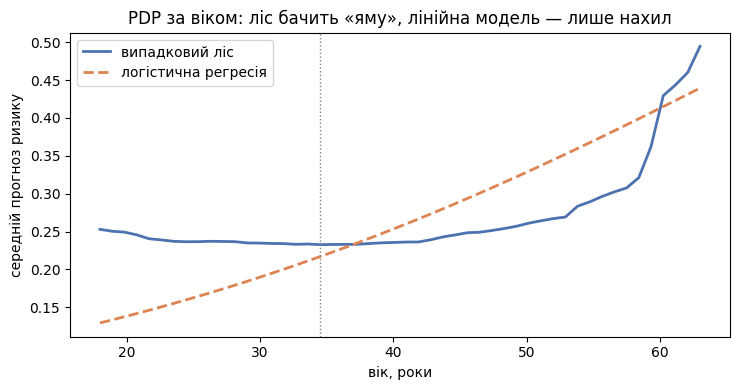

,частка_відтоку,клієнтів
вік,,
"[0, 25)",0.274,164
"[25, 35)",0.202,267
"[35, 45)",0.167,330
"[45, 55)",0.275,262
"[55, 100)",0.571,177


мінімум ризику в лісу: вік 35 років


In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

lr_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
pd_rf = partial_dependence(model, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=50)
pd_lr = partial_dependence(lr_model, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=50)
AGE0 = float(pd_rf['grid_values'][0][np.argmin(pd_rf['average'][0])])

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(pd_rf['grid_values'][0], pd_rf['average'][0], color='#4C72B0', lw=2, label='випадковий ліс')
ax.plot(pd_lr['grid_values'][0], pd_lr['average'][0], color='#DD8452', lw=2, ls='--', label='логістична регресія')
ax.axvline(AGE0, color='grey', lw=1, ls=':')
ax.set_xlabel('вік, роки')
ax.set_ylabel('середній прогноз ризику')
ax.set_title('PDP за віком: ліс бачить «яму», лінійна модель — лише нахил')
ax.legend()
plt.tight_layout()
plt.show()

age_emp = raw.groupby(pd.cut(raw['вік'], [0, 25, 35, 45, 55, 100], right=False))[TARGET].agg(частка_відтоку='mean', клієнтів='size')
display(age_emp.round(3))
print('мінімум ризику в лісу: вік %.0f років' % AGE0)

In [39]:
NONLINEAR_MEANING = ('ризик найвищий у наймолодших і найстарших клієнтів і найнижчий близько %.0f років; у сирих даних відтік '
                     '%.0f %% до 25 років, %.0f %% у 35–44 і %.0f %% від 55; можливе пояснення — молоді легко переходять до конкурентів '
                     'за акціями, а старші частіше відмовляються від послуги взагалі'
                     % (AGE0, age_emp['частка_відтоку'].iloc[0] * 100, age_emp['частка_відтоку'].iloc[2] * 100,
                        age_emp['частка_відтоку'].iloc[4] * 100))
NONLINEAR_FIX = ('додати ознаку «квадрат відхилення віку від %.0f років»: вона зростає в обидва боки від мінімуму, '
                 'і лінійна модель отримає «яму» як одну змінну' % AGE0)
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

ризик найвищий у наймолодших і найстарших клієнтів і найнижчий близько 35 років; у сирих даних відтік 27 % до 25 років, 17 % у 35–44 і 57 % від 55; можливе пояснення — молоді легко переходять до конкурентів за акціями, а старші частіше відмовляються від послуги взагалі
додати ознаку «квадрат відхилення віку від 35 років»: вона зростає в обидва боки від мінімуму, і лінійна модель отримає «яму» як одну змінну


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
Xq = FINAL_X.copy()
Xq['вік_відхилення_квадрат'] = (Xq['вік'] - AGE0) ** 2
auc_q = cross_val_score(make_pipe(Xq, logreg()), Xq, y, cv=cv, scoring='roc_auc')
mq, hq = paired(auc5, auc_q)
print('логістична на FINAL_X          : AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('логістична + (вік − %.0f)²       : AUC %.3f ± %.3f' % (AGE0, auc_q.mean(), auc_q.std()))
print('приріст: %+.4f ± %.4f   %s' % (mq, hq, 'значуще' if abs(mq) > hq else 'у межах шуму'))

логістична на FINAL_X          : AUC 0.834 ± 0.031
логістична + (вік − 35)²       : AUC 0.855 ± 0.030
приріст: +0.0218 ± 0.0053   значуще


In [41]:
QUAD_GAIN = float(mq)
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0218


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

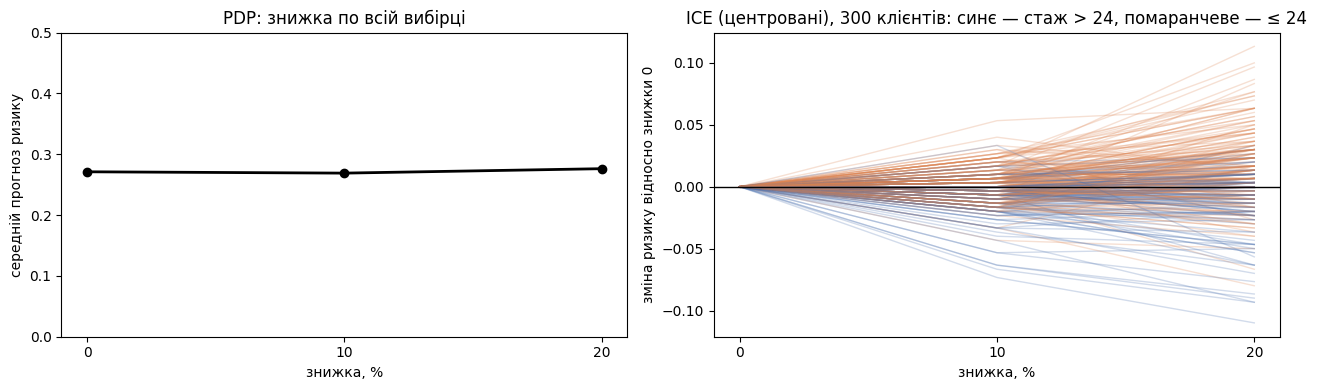

PDP по всій вибірці: {0.0: 0.271, 10.0: 0.269, 20.0: 0.276}
ICE: у 571 клієнтів ризик при знижці 20 % вищий, ніж без знижки, у 405 — нижчий
середня зміна ризику від 0 до 20 %: стаж ≤ 24 — +0.017, стаж > 24 — -0.013


In [42]:
DISC = 'знижка_відсоток'
TENURE_CUT = 24
pd_disc = partial_dependence(model, FINAL_X, [DISC], kind='both')
grid_disc = pd_disc['grid_values'][0]
ice = pd_disc['individual'][0]
old = (FINAL_X['місяців_обслуговування'] > TENURE_CUT).to_numpy()

rng = np.random.default_rng(SEED)
shown = rng.choice(len(FINAL_X), 300, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(grid_disc, pd_disc['average'][0], marker='o', color='k', lw=2)
ax[0].set_ylim(0, 0.5)
ax[0].set_xticks(grid_disc)
ax[0].set_xlabel('знижка, %')
ax[0].set_ylabel('середній прогноз ризику')
ax[0].set_title('PDP: знижка по всій вибірці')
for i in shown:
    ax[1].plot(grid_disc, ice[i] - ice[i][0], color='#4C72B0' if old[i] else '#DD8452', alpha=0.25, lw=1)
ax[1].axhline(0, color='k', lw=1)
ax[1].set_xticks(grid_disc)
ax[1].set_xlabel('знижка, %')
ax[1].set_ylabel('зміна ризику відносно знижки 0')
ax[1].set_title('ICE (центровані), 300 клієнтів: синє — стаж > 24, помаранчеве — ≤ 24')
plt.tight_layout()
plt.show()

ice_delta = pd.Series(ice[:, -1] - ice[:, 0])
print('PDP по всій вибірці:', dict(zip(grid_disc.tolist(), pd_disc['average'][0].round(3).tolist())))
print('ICE: у %d клієнтів ризик при знижці 20 %% вищий, ніж без знижки, у %d — нижчий'
      % ((ice_delta > 0.005).sum(), (ice_delta < -0.005).sum()))
print('середня зміна ризику від 0 до 20 %%: стаж ≤ %d — %+.3f, стаж > %d — %+.3f'
      % (TENURE_CUT, ice_delta[~old].mean(), TENURE_CUT, ice_delta[old].mean()))

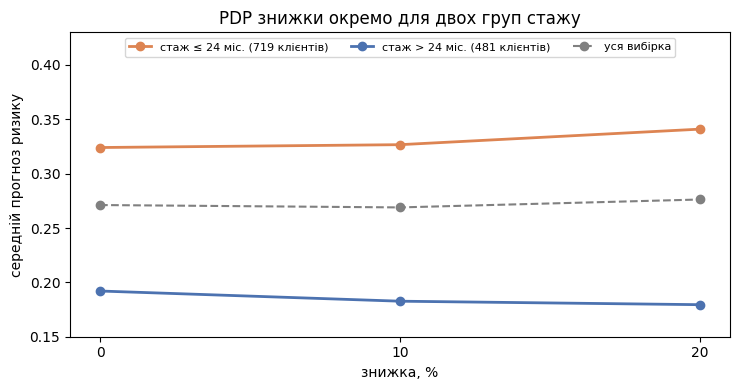

,стаж ≤ 24 міс.,стаж > 24 міс.
0.0,0.324,0.192
10.0,0.327,0.183
20.0,0.341,0.179


In [43]:
pd_groups = {}
fig, ax = plt.subplots(figsize=(7.5, 4))
for name, mask, col in [('стаж ≤ %d міс.' % TENURE_CUT, ~old, '#DD8452'), ('стаж > %d міс.' % TENURE_CUT, old, '#4C72B0')]:
    r = partial_dependence(model, FINAL_X[mask], [DISC], kind='average')
    pd_groups[name] = r['average'][0]
    ax.plot(r['grid_values'][0], r['average'][0], marker='o', color=col, lw=2, label='%s (%d клієнтів)' % (name, mask.sum()))
ax.plot(grid_disc, pd_disc['average'][0], marker='o', color='grey', ls='--', label='уся вибірка')
ax.set_xticks(grid_disc)
ax.set_ylim(0.15, 0.43)
ax.set_xlabel('знижка, %')
ax.set_ylabel('середній прогноз ризику')
ax.set_title('PDP знижки окремо для двох груп стажу')
ax.legend(loc='upper center', ncol=3, fontsize=8)
plt.tight_layout()
plt.show()
display(pd.DataFrame(pd_groups, index=grid_disc).round(3))

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
group = np.where(raw['місяців_обслуговування'] > TENURE_CUT, 'стаж > 24', 'стаж ≤ 24')
emp_tab = raw.assign(група=group).pivot_table(index=DISC, columns='група', values=TARGET, aggfunc=['mean', 'size'])
display(emp_tab.round(3))

mean                size          
група           стаж > 24 стаж ≤ 24 стаж > 24 стаж ≤ 24
знижка_відсоток                                        
0                   0.253     0.324       166       306
10                  0.128     0.332       187       217
20                  0.039     0.434       128       196

In [45]:
_new = emp_tab[('mean', 'стаж ≤ 24')] * 100
_old = emp_tab[('mean', 'стаж > 24')] * 100
INTERACTION_FOUND = ('у клієнтів зі стажем до 24 міс. знижка відтоку не зменшує: %.0f %% без знижки, %.0f %% при 10 %% і %.0f %% при 20 %%; '
                     'у давніх клієнтів — навпаки: %.0f %% → %.0f %% → %.0f %%; ефекти протилежні, тому PDP по всій вибірці майже плаский '
                     '(%.3f → %.3f), хоча в кожній групі ефект сильний'
                     % (*_new.values, *_old.values, pd_disc['average'][0][0], pd_disc['average'][0][-1]))
BUSINESS_ACTION = ('знижку пропонувати клієнтам зі стажем понад 24 міс., бо саме в них вона пов’язана з утриманням; новим клієнтам '
                   'знижка не допомагає, для них шукати іншу причину відтоку; ефект перевірити A/B-тестом, бо з CRM не видно, '
                   'кому і чому знижку давали')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

у клієнтів зі стажем до 24 міс. знижка відтоку не зменшує: 32 % без знижки, 33 % при 10 % і 43 % при 20 %; у давніх клієнтів — навпаки: 25 % → 13 % → 4 %; ефекти протилежні, тому PDP по всій вибірці майже плаский (0.271 → 0.276), хоча в кожній групі ефект сильний
знижку пропонувати клієнтам зі стажем понад 24 міс., бо саме в них вона пов’язана з утриманням; новим клієнтам знижка не допомагає, для них шукати іншу причину відтоку; ефект перевірити A/B-тестом, бо з CRM не видно, кому і чому знижку давали


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()
short = [n.split('__', 1)[1] for n in feat_names]

SAMPLE = min(300, Xte_t.shape[0])
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
base_value = float(np.ravel(expl.expected_value)[-1])
print('матриця значень Шеплі:', np.shape(sv1))
print('базовий рівень (середній прогноз): %.3f' % base_value)

матриця значень Шеплі: (300, 91)
базовий рівень (середній прогноз): 0.273


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

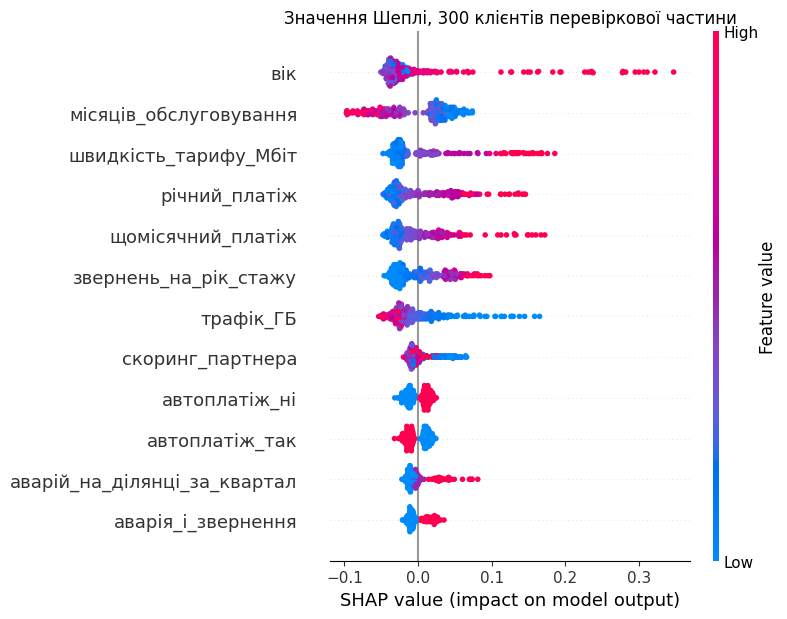

,середній |внесок|
вік,0.0463
місяців_обслуговування,0.0405
швидкість_тарифу_Мбіт,0.0375
річний_платіж,0.0356
номер_договору_серія,0.0334
щомісячний_платіж,0.0297
звернень_на_рік_стажу,0.0286
трафік_ГБ,0.0283


вік 0–24: середній внесок -0.023 (38 клієнтів)
вік 25–34: середній внесок -0.036 (62 клієнтів)
вік 35–44: середній внесок -0.036 (86 клієнтів)
вік 45–54: середній внесок -0.010 (69 клієнтів)
вік 55–99: середній внесок +0.148 (45 клієнтів)
напрям: високий вік, висока швидкість тарифу й великий платіж (червоні точки) штовхають ризик угору, а довгий стаж, великий трафік і автоплатіж — униз; однаковість: для стажу, швидкості й платежу колір змінюється вздовж осі монотонно, а вік діє не однаково: у наймолодших внесок -0.023, у віці 25–34 — -0.036, а від 55 різко +0.148 — та сама «яма», що й на PDP


In [47]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=short, max_display=12, show=False)
plt.title('Значення Шеплі, 300 клієнтів перевіркової частини')
plt.tight_layout()
plt.show()

shap_mean = pd.Series(np.abs(sv1).mean(axis=0), index=feat_names).groupby(to_source).sum().sort_values(ascending=False)
display(shap_mean.head(8).round(4).to_frame('середній |внесок|'))

_age_sv = sv1[:, list(feat_names).index('num__вік')]
_age = Xte['вік'].to_numpy()[:SAMPLE]
for lo, hi in [(0, 25), (25, 35), (35, 45), (45, 55), (55, 100)]:
    _m = (_age >= lo) & (_age < hi)
    print('вік %d–%d: середній внесок %+.3f (%d клієнтів)' % (lo, hi - 1, _age_sv[_m].mean(), _m.sum()))

_age_by = {(lo, hi): _age_sv[(_age >= lo) & (_age < hi)].mean() for lo, hi in [(0, 25), (25, 35), (55, 100)]}
SHAP_READING = ('напрям: високий вік, висока швидкість тарифу й великий платіж (червоні точки) штовхають ризик угору, а довгий стаж, '
                'великий трафік і автоплатіж — униз; однаковість: для стажу, швидкості й платежу колір змінюється вздовж осі монотонно, '
                'а вік діє не однаково: у наймолодших внесок %+.3f, у віці 25–34 — %+.3f, а від 55 різко %+.3f — та сама «яма», що й на PDP'
                % (_age_by[(0, 25)], _age_by[(25, 35)], _age_by[(55, 100)]))
print(SHAP_READING)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
risk_te = model.predict_proba(Xte)[:SAMPLE, 1]
idx = int(np.argmax(risk_te))
print('ризик клієнта: %.3f' % risk_te[idx])

contrib = pd.Series(sv1[idx], index=feat_names)
contrib_src = contrib.groupby(to_source).sum()
top_c = contrib_src.reindex(contrib_src.abs().sort_values(ascending=False).index).head(6)
client = Xte.iloc[idx]
display(pd.DataFrame({'значення': [client[c] for c in top_c.index], 'внесок': top_c.round(3)}))
print('базовий рівень %.3f + сума всіх внесків %+.3f = %.3f' % (base_value, contrib.sum(), base_value + contrib.sum()))
display(client.to_frame('клієнт').T)

ризик клієнта: 0.847


,значення,внесок
щомісячний_платіж,710.03,0.150
річний_платіж,8441.1,0.136
швидкість_тарифу_Мбіт,1000.0,0.131
місяців_обслуговування,8.0,0.051
звернень_на_рік_стажу,3.0,0.046
номер_договору_серія,ном-040,0.016


базовий рівень 0.273 + сума всіх внесків +0.573 = 0.847


,вік,стать,місто,тариф,тип_підключення,спосіб_оплати,автоплатіж,кількість_послуг,місяців_обслуговування,швидкість_тарифу_Мбіт,щомісячний_платіж,знижка_відсоток,трафік_ГБ,кількість_звернень_у_підтримку,аварій_на_ділянці_за_квартал,середній_час_відповіді_хв,річний_платіж,номер_договору_серія,скоринг_партнера,дата_підключення,звернень_на_рік_стажу,новий_клієнт,аварія_і_звернення
клієнт,50.0,ж,дрогобич,максимальний,adsl,каса,ні,3.0,8.0,1000.0,710.03,0.0,126.0,2.0,0.0,25.0,8441.1,ном-040,520.444,320.0,3.0,1.0,0.0


In [49]:
_r = risk_te[idx]
EXPLANATION_FOR_MANAGER = ('Клієнтка платить %.0f грн на місяць (%.0f грн на рік) за найшвидший тариф — %.0f Мбіт. Серед клієнтів із такими '
                           'дорогими швидкісними тарифами договір розривають найчастіше, і саме це найбільше підняло оцінку. Додатково '
                           'насторожує, що вона з нами лише %.0f місяців і вже %.0f рази зверталась у підтримку. Імовірність, що вона піде '
                           'цього кварталу, — %.0f %% проти %.0f %% у середньому. Розмову варто почати з того, чи влаштовує її ціна за '
                           'швидкість: знижка клієнтам, які з нами менше двох років, за нашими даними не утримує.'
                           % (client['щомісячний_платіж'], client['річний_платіж'], client['швидкість_тарифу_Мбіт'],
                              client['місяців_обслуговування'], client['кількість_звернень_у_підтримку'], _r * 100, base_value * 100))
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Клієнтка платить 710 грн на місяць (8441 грн на рік) за найшвидший тариф — 1000 Мбіт. Серед клієнтів із такими дорогими швидкісними тарифами договір розривають найчастіше, і саме це найбільше підняло оцінку. Додатково насторожує, що вона з нами лише 8 місяців і вже 2 рази зверталась у підтримку. Імовірність, що вона піде цього кварталу, — 85 % проти 27 % у середньому. Розмову варто почати з того, чи влаштовує її ціна за швидкість: знижка клієнтам, які з нами менше двох років, за нашими даними не утримує.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'місяців_обслуговування'
SHAP_NOT_CAUSAL_WHY = ('друга ознака за середнім |внеском| Шеплі (%.4f), а в найризиковішої клієнтки 8 місяців стажу додали %+.3f; '
                       'але стаж не можна змінити дзвінком, і зв’язок не причинний: давні клієнти лишаються тому, що їх влаштовує сервіс '
                       '(кого не влаштовував, ті пішли раніше), а не тому, що минули місяці; «модель цим користується» означає, що за стажем '
                       'вона відрізняє ризикових, «це причина» — що зміна ознаки змінила б результат, а таких даних у нас немає'
                       % (shap_mean['місяців_обслуговування'], contrib_src['місяців_обслуговування']))
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

місяців_обслуговування — друга ознака за середнім |внеском| Шеплі (0.0405), а в найризиковішої клієнтки 8 місяців стажу додали +0.051; але стаж не можна змінити дзвінком, і зв’язок не причинний: давні клієнти лишаються тому, що їх влаштовує сервіс (кого не влаштовував, ті пішли раніше), а не тому, що минули місяці; «модель цим користується» означає, що за стажем вона відрізняє ризикових, «це причина» — що зміна ознаки змінила б результат, а таких даних у нас немає


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",номер_договору_серія,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",місяців_обслуговування,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = ('Шеплі і дубльована пара: у поясненні найризиковішої клієнтки два з трьох найбільших внесків — щомісячний платіж (%+.3f) '
                 'і річний платіж (%+.3f); менеджер прочитає це як дві окремі причини, але r = %.4f — це одна інформація, ціна тарифу, '
                 'і Шеплі просто поділив її внесок між двома копіями (разом %+.3f); прибери одну колонку — і весь внесок перейде на другу; '
                 'тому в поясненнях дубльовані ознаки треба об’єднувати, а «три найбільші внески» тут — це два чинники: ціна і швидкість'
                 % (contrib_src['щомісячний_платіж'], contrib_src['річний_платіж'], corr.loc[DUP_PAIR[0], DUP_PAIR[1]],
                    contrib_src['щомісячний_платіж'] + contrib_src['річний_платіж']))
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

Шеплі і дубльована пара: у поясненні найризиковішої клієнтки два з трьох найбільших внесків — щомісячний платіж (+0.150) і річний платіж (+0.136); менеджер прочитає це як дві окремі причини, але r = 0.9993 — це одна інформація, ціна тарифу, і Шеплі просто поділив її внесок між двома копіями (разом +0.286); прибери одну колонку — і весь внесок перейде на другу; тому в поясненнях дубльовані ознаки треба об’єднувати, а «три найбільші внески» тут — це два чинники: ціна і швидкість


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
TOP_N = 100
risk_all = model.predict_proba(Xte)[:, 1]
top = yte.iloc[np.argsort(-risk_all)[:TOP_N]]
lift = top.mean() / yte.mean()
print('перевіркова частина: %d клієнтів, відтік %.3f' % (len(yte), yte.mean()))
print('топ-%d за ризиком: пішли %d, частка %.3f' % (TOP_N, top.sum(), top.mean()))
print('навмання серед %d очікувалось би %.0f' % (TOP_N, TOP_N * yte.mean()))
print('lift = %.2f' % lift)

перевіркова частина: 360 клієнтів, відтік 0.272
топ-100 за ризиком: пішли 60, частка 0.600
навмання серед 100 очікувалось би 27
lift = 2.20


In [54]:
LIFT_MEANING = ('якщо обдзвонити 100 клієнтів із найвищим ризиком, серед них %d справді йдуть замість ≈ %.0f при випадковому виборі, '
                'тобто кожен дзвінок у %.1f раза частіше потрапляє на того, кого треба утримувати'
                % (top.sum(), TOP_N * yte.mean(), lift))
assert LIFT_MEANING
print(LIFT_MEANING)

якщо обдзвонити 100 клієнтів із найвищим ризиком, серед них 60 справді йдуть замість ≈ 27 при випадковому виборі, тобто кожен дзвінок у 2.2 раза частіше потрапляє на того, кого треба утримувати


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_04.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [ ]:
_sc = scan.set_index('ознака')['показник']
_br = by_branch['частка'] * 100
_ex = excess.loc[SUSPECT_BRANCHES, 'надлишок'] * 100
_q = by_q['частка'] * 100
_bp = branch_profile
_rf_vs, _hgb_vs = PAIRED['випадковий ліс'], PAIRED['гістограмний бустинг']
_t = cmp_models['с на 100 навчань']

REPORT = '\n\n'.join([
    '1. Метрика — AUC. Частка відтоку %.3f, тож модель «ніхто не піде» дала б точність %.3f і жодного клієнта для утримання. '
    'AUC не залежить від порога і показує, чи ставить модель тих, хто піде, вище за тих, хто лишиться.'
    % (raw[TARGET].mean(), BASELINE_ACC),

    '2. Викинуто: id_клієнта (ідентифікатор з реєстрації, модель його лише запам’ятовує); сума_повернення_депозиту (з’являється '
    'в день закриття договору); код_причини_закриття (у момент розірвання); оцінка_ризику_менеджером (після розмов менеджера '
    'з клієнтом, коли той уже показав намір піти); філія (існує в момент прогнозу, але несе артефакт збору, див. п. 4). '
    'Детектор 5.1 знайшов лише два цільові витоки (показник %.3f і %.3f). Оцінку менеджера він не бачить, бо поле заповнене '
    'в усіх %d клієнтів, а детектор дивиться лише на факт заповненості; витік сидить у значеннях: при оцінці 1 пішли %.0f %%, '
    'при оцінці 5 — %.0f %%. Після її вилучення AUC впала з %.3f до %.3f.'
    % (_sc['сума_повернення_депозиту'], _sc['код_причини_закриття'], len(raw),
       manager['частка_відтоку'].iloc[0] * 100, manager['частка_відтоку'].iloc[-1] * 100, auc2.mean(), auc3.mean()),

    '3. Чесне число — AUC %.3f ± %.3f (логістична регресія, 5 згорток × 4 повтори, без витоків і без філії). Розкид %.3f '
    'приблизно в %.0f разів більший за 0.004, тож різниця 0.004 між двома моделями нічого не означає без парного порівняння '
    'на тих самих згортках: навіть ліс проти логістичної дає %+.4f ± %.4f, тобто в межах шуму.'
    % (HONEST_AUC, auc4.std(), auc4.std(), auc4.std() / 0.004, *_rf_vs),

    '4. Так. У філіях %s відтік %.0f %% і %.0f %% проти %.0f–%.0f %% в інших, і це на %.0f–%.0f п. п. більше, ніж очікується '
    'за ознаками самих клієнтів; за кварталами підключення сходинки немає (%.0f–%.0f %%). Ті самі чесні ознаки вгадують ці філії '
    'з AUC %.3f, тобто класи не порівнянні. З філією AUC %.3f, без неї %.3f. В іншій філії моделі можна довіряти лише після '
    'перевірки на її даних: назви філії модель не знає, але ознаки, якими Центр і Захід відрізняються від інших, лишились '
    '(середній вік %.1f проти %.1f, швидкість тарифу %.0f проти %.0f Мбіт).'
    % (' і '.join(SUSPECT_BRANCHES), *_br[SUSPECT_BRANCHES], _br.drop(SUSPECT_BRANCHES).min(), _br.drop(SUSPECT_BRANCHES).max(),
       _ex.min(), _ex.max(), _q.min(), _q.max(), auc_src.mean(), auc3.mean(), auc4.mean(),
       _bp.loc['Центр і Захід', 'вік'], _bp.loc['інші філії', 'вік'],
       _bp.loc['Центр і Захід', 'швидкість_тарифу_Мбіт'], _bp.loc['інші філії', 'швидкість_тарифу_Мбіт']),

    '5. Нові ознаки дали логістичній %+.4f ± %.4f (%.1f с на 100 навчань), складніша модель: ліс %+.4f ± %.4f (%.1f с), '
    'бустинг %+.4f ± %.4f (%.1f с); усе в межах шуму, тобто жоден шлях не дав приросту, а складніші моделі в %.0f і %.0f разів '
    'повільніші. Найбільше дала одна ознака, підказана PDP: (вік − %.0f)² підняла AUC логістичної на %+.4f ± %.4f, і це значуще.'
    % (m5, h5, _t['логістична регресія'], *_rf_vs, _t['випадковий ліс'], *_hgb_vs, _t['гістограмний бустинг'],
       _t['випадковий ліс'] / _t['логістична регресія'], _t['гістограмний бустинг'] / _t['логістична регресія'], AGE0, mq, hq),

    '6. номер_договору_серія: 1-ше місце за вбудованою важливістю (%.3f), а перестановочна %+.4f. Дерево обирає розбиття за '
    'зменшенням неоднорідності на навчальних даних; %d дамі-стовпців серії — це %d додаткових порогів, і серед груп по %d–%d '
    'клієнтів завжди є така, де відтік випадково інший. Вбудована важливість цього не штрафує, бо рахується на тих самих '
    'навчальних даних.'
    % (both.loc[FAKE_IMPORTANT, 'вбудована'], both.loc[FAKE_IMPORTANT, 'перестановочна'], _n_levels, _n_levels,
       _sizes.min(), _sizes.max()),

    '7. щомісячний_платіж і річний_платіж (r = %.4f): у повній моделі перестановочна важливість %.4f і %.4f, без річного платежу '
    'щомісячний має %.4f (ранг %d → %d). Це не вада: метод відповідає, наскільки гірше без цієї ознаки, а з дублем модель бере ту '
    'саму інформацію з другої колонки. Хибний лише висновок «мала важливість — можна викинути обидві».'
    % (corr.loc[DUP_PAIR[0], DUP_PAIR[1]], perm_imp[DUP_PAIR[0]], perm_imp[DUP_PAIR[1]], perm_wo[DUP_PAIR[0]], RANK_FULL, RANK_WO),

    '8. вік: PDP лісу спадає до ≈ %.0f років (мінімум %.3f), а потім різко зростає (до %.3f); у сирих даних відтік %.0f %% до 25 '
    'років, %.0f %% у 35–44 і %.0f %% від 55. Логістична регресія без втручання цього не бачить: її PDP монотонний. Ознака '
    '(вік − %.0f)² підняла її AUC з %.3f до %.3f (%+.4f ± %.4f).'
    % (AGE0, pd_rf['average'][0].min(), pd_rf['average'][0].max(), age_emp['частка_відтоку'].iloc[0] * 100,
       age_emp['частка_відтоку'].iloc[2] * 100, age_emp['частка_відтоку'].iloc[4] * 100, AGE0, auc5.mean(), auc_q.mean(), mq, hq),

    '9. знижка_відсоток: PDP по всій вибірці майже плаский (%.3f → %.3f → %.3f при 0, 10, 20 %%). ICE показав, що криві йдуть '
    'у різні боки: у %d клієнтів ризик при знижці 20 %% вищий, ніж без знижки, у %d — нижчий. PDP по групах: стаж ≤ 24 міс. '
    '%.3f → %.3f, стаж > 24 міс. %.3f → %.3f. Сирі дані показують те саме, але сильніше: стаж ≤ 24 — %.0f → %.0f → %.0f %%, '
    'стаж > 24 — %.0f → %.0f → %.0f %%; ліс відтворює напрям, але згладжує величину.'
    % (*pd_disc['average'][0], (ice_delta > 0.005).sum(), (ice_delta < -0.005).sum(),
       pd_groups['стаж ≤ 24 міс.'][0], pd_groups['стаж ≤ 24 міс.'][-1], pd_groups['стаж > 24 міс.'][0],
       pd_groups['стаж > 24 міс.'][-1], *_new.values, *_old.values),

    '10. %s: %s.' % (SHAP_NOT_CAUSAL_FEATURE, SHAP_NOT_CAUSAL_WHY),

    '11. Серед 100 клієнтів із найвищим ризиком на перевірковій частині пішли %d (%.0f %%) проти %.0f %% в усій частині: lift %.2f, '
    'тобто кожен дзвінок у %.1f раза частіше потрапляє на того, хто справді йде. Застереження: список показує, хто піде, а не кого '
    'втримає дзвінок; знижка за нашими даними пов’язана з утриманням лише в клієнтів зі стажем понад 24 міс., а новачкам потрібна '
    'інша пропозиція. До того ж lift — одне число з однієї відкладеної частини (там AUC %.3f проти %.3f у крос-валідації).'
    % (top.sum(), top.mean() * 100, yte.mean() * 100, lift, lift, auc_hold, HONEST_AUC),

    'Декларація про використання ШІ: так, користувався ШІ-асистентом Claude — для написання коду функцій to_number, '
    'build_X, make_pipe, leak_scan, paired, add_features і графіків, для пошуку пасток у даних і для чернетки текстових відповідей. '
    'Самостійно перевірив: що ноутбук проходить Restart & Run All без помилок; що числа у звіті беруться зі змінних ноутбука; '
    'що викинуті стовпці справді не існують у момент прогнозу, а справжні ознаки (кількість звернень, аварії) лишились; '
    'що висновки про знижку і вік збігаються із сирими даними (таблиці 10.2 і 10.3б).',
])
print(REPORT)

1. Метрика — AUC. Частка відтоку 0.273, тож модель «ніхто не піде» дала б точність 0.728 і жодного клієнта для утримання. AUC не залежить від порога і показує, чи ставить модель тих, хто піде, вище за тих, хто лишиться.

2. Викинуто: id_клієнта (ідентифікатор з реєстрації, модель його лише запам’ятовує); сума_повернення_депозиту (з’являється в день закриття договору); код_причини_закриття (у момент розірвання); оцінка_ризику_менеджером (після розмов менеджера з клієнтом, коли той уже показав намір піти); філія (існує в момент прогнозу, але несе артефакт збору, див. п. 4). Детектор 5.1 знайшов лише два цільові витоки (показник 1.000 і 1.000). Оцінку менеджера він не бачить, бо поле заповнене в усіх 1200 клієнтів, а детектор дивиться лише на факт заповненості; витік сидить у значеннях: при оцінці 1 пішли 0 %, при оцінці 5 — 100 %. Після її вилучення AUC впала з 0.972 до 0.846.

3. Чесне число — AUC 0.834 ± 0.031 (логістична регресія, 5 згорток × 4 повтори, без витоків і без філії). Розки

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.